<a href="https://colab.research.google.com/github/ruffles0928/trading_strategy_backtests/blob/main/spy_monthly_ema_backtest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SPY Monthly EMA Strategy vs. Buy-and-Hold

**Two questions this notebook answers**

1. **Event study:** When SPY is in an uptrend on the **monthly chart** (EMA 9 > 15 > 65 > 200), and price pulls back to the 9-, 15- or 65-month EMA, how often does it **bounce to a higher high** versus **keep falling to a lower low** — and what is the typical gain or loss?
2. **Backtest:** Trading your rules (buy when price hits the 15 EMA in an uptrend; sell when the candle is overstretched with RSI > 80, or when price closes below the 9 EMA), with no look-ahead and a trading cost — do you beat simply **buying and holding SPY**?

**Data:** SPY monthly candles (open, high, low, close) for its full history since 1993. The EMAs are calculated in this notebook from the monthly closes.

Your strategy is compared with **buy-and-hold** in a results table and three charts (growth of $1, metric-by-metric bars, and your trades on the price chart).

**How to use:** `Runtime → Run all`. Each code cell has an explanation above it — read those to be able to explain every line in an interview.

## Step 1 — Install and import libraries

| Line | What it does |
|---|---|
| `!pip install -q yfinance tabulate` | `!` runs a shell command inside Colab. Installs **yfinance** (downloads Yahoo Finance prices) and **tabulate** (prints tables as Markdown for the README). `-q` = quiet output. |
| `import numpy as np` | NumPy: fast math on arrays. `np` is the standard nickname. |
| `import pandas as pd` | pandas: data tables (**DataFrames**) where each row is a date and each column a variable. |
| `import yfinance as yf` | The price downloader. |
| `import matplotlib.pyplot as plt` | Charting library. |
| `from matplotlib.ticker import PercentFormatter, FuncFormatter` | Axis formatting: show 0.25 as "25%", and log-scale axes as plain numbers ("$5", "400") instead of "5×10⁰". |

In [1]:
!pip install -q yfinance tabulate

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

## Step 2 — Settings (all assumptions in one place)

Keeping every number here avoids "magic numbers" buried in the code; to test a different assumption you change one line.

| Setting | Meaning / why |
|---|---|
| `TICKER = "SPY"` | The S&P 500 ETF. Its history starts in January 1993. |
| `INTERVAL = "1mo"` | Monthly candles: each row is one month (open, high, low, close of that month). |
| `PERIODS_PER_YEAR = 12` | Used to annualize monthly numbers. |
| `EMA_SPANS` | Your four EMAs — now measured in **months**. |
| `WARMUP_BARS = 200` | An EMA is built from past prices, so the 200-month EMA needs ~200 months of history before it means anything. Those first 200 months (1993 to ~2009) are used only to calculate the EMAs; results are measured from ~2009 onward. |
| `COST = 0.0005` | 0.05% (5 basis points) charged every time we buy **or** sell — commission + bid/ask spread. |
| `SWING_LOOKBACK = 12` | The "previous high" is the highest high of the 12 months before the pullback. |
| `MAX_HOLD = 36` | In the event study, if neither a higher high nor a lower low happens within 36 months, we call it a timeout. |
| `RSI_PERIOD = 14` | RSI look-back in months. Set it to the same number your chart uses so the values match. |
| `RSI_LEVEL = 80` | RSI above this = overbought (part of the overstretch sell). |
| `STRETCH_PCTL = 0.90` | "Far from EMA9" = the stretch % is in the top 10% of all **earlier** green candles. |

In [2]:
TICKER = "SPY"              # S&P 500 ETF, monthly history from 1993
INTERVAL = "1mo"            # monthly bars
PERIODS_PER_YEAR = 12

EMA_SPANS = [9, 15, 65, 200]
WARMUP_BARS = 200           # months used only to warm up the 200-month EMA
COST = 0.0005               # 0.05% per side (each buy and each sell)
SWING_LOOKBACK = 12         # months used to find the prior swing high
MAX_HOLD = 36               # event study: stop tracking after 36 months

RSI_PERIOD = 14             # match the RSI setting on your chart
RSI_LEVEL = 80              # overbought level
STRETCH_PCTL = 0.90         # 'far from EMA9' = top 10% of earlier green candles

## Step 3 — Download the full monthly history

| Line | What it does |
|---|---|
| `.history(period="max", interval=INTERVAL, ...)` | Downloads **all** available history as monthly bars. |
| `auto_adjust=True` | Adjusts prices for **dividends and splits**. SPY pays ~1.5%/yr in dividends, so buy-and-hold is measured as *total return*; without this it would look worse than it really is. |
| `raw[["Open", "High", "Low", "Close"]]` | Keeps only the four price columns (double brackets = a list of columns). `.dropna()` removes any month with missing data; `.copy()` makes an independent table. |
| `if df.index.tz is not None: ...` | Yahoo sometimes attaches a time zone to dates; removing it keeps date comparisons simple. |
| `.to_period("M").to_timestamp()` | Labels every row as the first day of its month, so each month has exactly one consistent date. |
| `df.index.duplicated(keep="last")` | Safety check: if Yahoo returns two rows for the same month, keep only the last. `~` means "not". |
| `this_month` / `df.index < this_month` | **Drops the current month**, because its bar isn't finished — its "close" is just today's price, which would be using an incomplete month. |
| `TEST_START = df.index[WARMUP_BARS]` | Results start at the 201st month, after the warm-up. |
| `print(...)`, `df.head()` | Always look at your data: first month, last month, number of months. |

In [3]:
raw = yf.Ticker(TICKER).history(period="max", interval=INTERVAL, auto_adjust=True)

df = raw[["Open", "High", "Low", "Close"]].dropna().copy()
if df.index.tz is not None:
    df.index = df.index.tz_localize(None)
df.index = df.index.to_period("M").to_timestamp()
df = df[~df.index.duplicated(keep="last")]

this_month = pd.Timestamp.today().to_period("M").to_timestamp()
df = df[df.index < this_month]

TEST_START = df.index[WARMUP_BARS]
TEST_END = df.index[-1]

print(f"{TICKER}: {len(df)} months, {df.index[0]:%b %Y} to {TEST_END:%b %Y}")
print(f"Test period (after {WARMUP_BARS}-month warm-up): {TEST_START:%b %Y} to {TEST_END:%b %Y}")
df.head()

SPY: 405 months, Jan 1993 to Sep 2026
Test period (after 200-month warm-up): Sep 2009 to Sep 2026


,Open,High,Low,Close
Date,,,,
1993-01-01,24.070643,24.070643,23.950889,24.053535
1993-02-01,24.070636,24.703623,23.437648,24.310144
1993-03-01,24.510911,25.215643,24.321837,24.854683
1993-04-01,24.889055,24.889055,23.806175,24.218700
1993-05-01,24.253078,25.112506,24.115569,24.871866


## Step 4 — Calculate the EMAs

**Formula:** EMA<sub>this month</sub> = α × Close<sub>this month</sub> + (1 − α) × EMA<sub>last month</sub>, where α = 2 / (span + 1).
For the 9-month EMA, α = 0.2: this month's close gets 20% weight and all past history 80%. Longer spans react more slowly.

| Line | What it does |
|---|---|
| `for span in EMA_SPANS:` | Repeats the next line for 9, 15, 65, 200. |
| `df[f"ema{span}"]` | Creates a new column; the f-string builds the name `ema9`, `ema15`, etc. |
| `.ewm(span=span, adjust=False).mean()` | pandas' exponentially weighted mean. `adjust=False` uses exactly the recursive formula above — the same way TradingView and most charting platforms draw an EMA, so the numbers match what you see on a monthly chart. |

In [4]:
for span in EMA_SPANS:
    df[f"ema{span}"] = df["Close"].ewm(span=span, adjust=False).mean()

df[["Close", "ema9", "ema15", "ema65", "ema200"]].tail()

,Close,ema9,ema15,ema65,ema200
Date,,,,,
2026-05-01,752.667114,683.367676,655.612690,504.528525,328.498305
2026-06-01,744.920227,695.678186,666.776132,511.813122,332.641807
2026-07-01,745.179626,705.578474,676.576569,518.884835,336.746661
2026-08-01,765.149963,717.492772,687.648243,526.347414,341.009380
2026-09-01,762.630005,726.520218,697.020963,533.507493,345.204611


## Step 5 — Turn your idea into exact rules

| Your idea | Rule in code |
|---|---|
| "I'm in an uptrend" | `uptrend` = EMA9 > EMA15 **and** EMA15 > EMA65 **and** EMA65 > EMA200. |
| …checked **before** the dip | `was_uptrend` = the stack was aligned **last month**. A pullback itself drags the 9-EMA down, so we ask "was the trend intact, and then price dipped?" |
| Count each dip once | `was_above_ema9` = last month's close was above the 9-EMA. So only the **first** month of a dip counts, not every month of the same dip. |
| "Price hit EMA 9, 15, 65" | `touch` = this month's **low** reached the EMA. If several were hit, we label the **deepest** one (65 is deeper than 15, which is deeper than 9). |
| Only test period | `df.index >= TEST_START` blanks out warm-up signals. |

Line notes:
- `&` means element-wise "and" between two columns of True/False. Each condition needs parentheses because `&` is evaluated before `>`.
- `.shift(1)` moves every value down one row, so each row sees **last month's** value. `fill_value=False` fills the empty first row.
- `np.select(conditions, labels, default)` checks the conditions **in order** and returns the label of the first one that's True — that's why EMA65 is listed first.

In [5]:
df["uptrend"] = (
    (df["ema9"] > df["ema15"])
    & (df["ema15"] > df["ema65"])
    & (df["ema65"] > df["ema200"])
)

was_uptrend = df["uptrend"].shift(1, fill_value=False)
was_above_ema9 = df["Close"].shift(1) > df["ema9"].shift(1)

df["touch"] = np.select(
    [df["Low"] <= df["ema65"], df["Low"] <= df["ema15"], df["Low"] <= df["ema9"]],
    ["EMA65", "EMA15", "EMA9"],
    default="none",
)

df["signal"] = (
    was_uptrend
    & was_above_ema9
    & (df["touch"] != "none")
    & (df.index >= TEST_START)
)

print("Pullback signals found:", int(df["signal"].sum()))
print(df.loc[df["signal"], "touch"].value_counts())
df.loc[df["signal"], ["Close", "Low", "ema9", "ema15", "ema65", "touch"]]

Pullback signals found: 37
touch
EMA9     23
EMA15    13
EMA65     1
Name: count, dtype: int64


,Close,Low,ema9,ema15,ema65,touch
Date,,,,,,
2011-06-01,101.108200,96.679881,97.773974,93.867680,85.951478,EMA9
2011-08-01,93.638313,84.482870,97.156701,94.409718,86.570355,EMA65
2011-11-01,96.255920,89.486662,95.612845,94.189436,87.176176,EMA15
2011-12-01,97.261665,93.022451,95.942609,94.573465,87.481797,EMA15
2012-05-01,102.334885,100.840378,102.565616,100.046461,90.090662,EMA9
2012-07-01,107.747444,103.749263,104.229523,101.713600,91.107541,EMA9
2012-11-01,111.815109,105.954946,108.650501,105.847390,93.490239,EMA9
2014-02-01,150.554977,140.388143,140.541206,134.275833,108.580306,EMA9
2014-10-01,165.249130,149.073296,157.250447,151.059763,119.555299,EMA15


## Step 6 — Event study: did the pullback bounce or keep falling?

For every signal month we follow price forward, month by month, until one of these happens:

| Outcome | Definition |
|---|---|
| **higher high** (bounce) | A monthly close **above** the highest high of the 12 months before the dip → the uptrend resumed. |
| **lower low** (kept falling) | A monthly close **below** the low of the touch month → the dip failed. |
| **timeout** | Neither within 36 months. |

Return = exit close ÷ touch-month close − 1. We use **closes** (not highs/lows) because a monthly bar can't tell us whether its high or its low came first.

> This step is a *measurement* — it deliberately looks forward to see what happened. The no-look-ahead rule applies to the trading backtest in Steps 8–9.

Line notes:
- `np.where(df["signal"])[0]` → the row numbers of all signal months.
- `.iloc[i]` reads a value by row number (as opposed to `.loc`, which reads by date label).
- `df["High"].iloc[i - SWING_LOOKBACK:i].max()` → highest high of the 12 rows **before** row `i` (the end of a slice is excluded).
- `min(i + MAX_HOLD, len(df) - 1)` stops the search at 36 months or at the end of the data, whichever comes first.
- The inner `for j in range(...)` walks forward one month at a time; `break` exits the loop at the first outcome.
- Collecting results as a list of dictionaries and converting once with `pd.DataFrame(events)` is the standard fast pattern.
- `summarize(group)` builds one row of statistics. `(group["outcome"] == "higher high").mean()` works because True counts as 1 and False as 0, so the mean is a percentage.

In [6]:
events = []

for i in np.where(df["signal"])[0]:
    if i + 1 >= len(df):
        continue                                   # signal in the last month: nothing to measure

    entry_price = df["Close"].iloc[i]
    stop_level = df["Low"].iloc[i]                 # low of the pullback month
    swing_high = df["High"].iloc[i - SWING_LOOKBACK:i].max()
    last_bar = min(i + MAX_HOLD, len(df) - 1)

    outcome = "timeout"
    for j in range(i + 1, last_bar + 1):
        close_j = df["Close"].iloc[j]
        if close_j > swing_high:
            outcome = "higher high"
            break
        if close_j < stop_level:
            outcome = "lower low"
            break

    events.append({
        "date": df.index[i],
        "ema_touched": df["touch"].iloc[i],
        "outcome": outcome,
        "return": df["Close"].iloc[j] / entry_price - 1,
        "months": j - i,
    })

events = pd.DataFrame(events)

def summarize(group):
    return pd.Series({
        "events": len(group),
        "bounce_rate": (group["outcome"] == "higher high").mean(),
        "fail_rate": (group["outcome"] == "lower low").mean(),
        "timeout_rate": (group["outcome"] == "timeout").mean(),
        "avg_return": group["return"].mean(),
        "avg_return_bounce": group.loc[group["outcome"] == "higher high", "return"].mean(),
        "avg_return_fail": group.loc[group["outcome"] == "lower low", "return"].mean(),
        "avg_months": group["months"].mean(),
    })

rows = {ema: summarize(events[events["ema_touched"] == ema]) for ema in ["EMA9", "EMA15", "EMA65"]}
rows["All"] = summarize(events)
event_summary = pd.DataFrame(rows).T

event_summary.style.format({
    "events": "{:.0f}", "bounce_rate": "{:.1%}", "fail_rate": "{:.1%}", "timeout_rate": "{:.1%}",
    "avg_return": "{:.2%}", "avg_return_bounce": "{:.2%}", "avg_return_fail": "{:.2%}", "avg_months": "{:.1f}",
}, na_rep="–")

,events,bounce_rate,fail_rate,timeout_rate,avg_return,avg_return_bounce,avg_return_fail,avg_months
EMA9,23,69.6%,30.4%,0.0%,2.60%,6.43%,-6.16%,2.5
EMA15,13,69.2%,30.8%,0.0%,3.51%,9.58%,-10.15%,2.9
EMA65,1,100.0%,0.0%,0.0%,13.40%,13.40%,–,6.0
All,37,70.3%,29.7%,0.0%,3.21%,7.79%,-7.61%,2.7


## Step 7 — Sell indicators: RSI and the "overstretch" %

**RSI (Relative Strength Index, Wilder's method — the same as TradingView):**
1. Monthly change = this close − last close. *Gains* = positive changes (otherwise 0); *losses* = size of negative changes (otherwise 0).
2. Average gain and average loss, smoothed with α = 1 / 14.
3. RS = average gain ÷ average loss; **RSI = 100 − 100 ÷ (1 + RS)**. Above 80 = overbought.

**Stretch % (your formula)**, for each **green** candle (close > open):

> stretch % = (Open − EMA9) ÷ EMA9  e.g. open 550, EMA9 500 → 10%

**What counts as "far":** a green candle whose stretch is in the top 10% of all **earlier** green candles. We compare only with the past — setting the threshold from the full history would let a 2010 decision use information from 2025 (look-ahead bias).

Line notes:
- `.diff()` → this month minus last month. `.clip(lower=0)` keeps positive values and turns negatives into 0.
- `.ewm(alpha=1/RSI_PERIOD, adjust=False).mean()` → Wilder's smoothing.
- `df["Close"] > df["Open"]` → True for green candles.
- `.where(df["green"])` keeps the stretch on green candles and blanks (NaN) the red ones.
- `.expanding(min_periods=24).quantile(STRETCH_PCTL)` → for each month, the 90th percentile of all green-candle stretches **up to that month** (only once there are 24 green candles to compare with). Blanks are skipped.
- `.shift(1)` → each candle is compared only with candles **before** it.
- `describe(percentiles=...)` → the distribution of all stretch %s: mean, median and the 75/90/95/99th percentiles.
- The histogram shows the same distribution as a chart; the last table lists every month that met **both** sell conditions.

Green monthly candles: 257
mean      2.22%
std       4.94%
min     -23.10%
50%       3.50%
75%       5.21%
90%       7.16%
95%       7.80%
99%       9.02%
max      10.41%

Green candles with RSI > 80: 38
Overstretched (far from EMA9 AND RSI > 80): 6

Top 15 most stretched green candles:
             Open   ema9 stretch  rsi
Date                                 
2021-05-01 389.77 353.01  10.41% 75.5
1998-04-01  67.54  61.27  10.24% 84.0
2020-12-01 338.61 310.05   9.21% 69.1
1999-01-01  76.30  70.08   8.87% 74.7
1997-02-01  47.33  43.49   8.83% 84.0
2021-06-01 393.97 362.22   8.76% 76.7
1997-06-01  51.71  47.58   8.67% 82.9
2009-12-01  82.57  76.22   8.34% 54.0
1998-03-01  64.44  59.54   8.22% 83.4
2011-01-01  96.18  88.97   8.11% 63.9
2024-03-01 494.38 457.39   8.09% 70.2
1997-07-01  53.62  49.61   8.07% 86.0
1995-12-01  35.95  33.30   7.95% 86.0
2010-04-01  88.06  81.71   7.76% 59.2
2021-04-01 370.22 343.68   7.72% 75.1


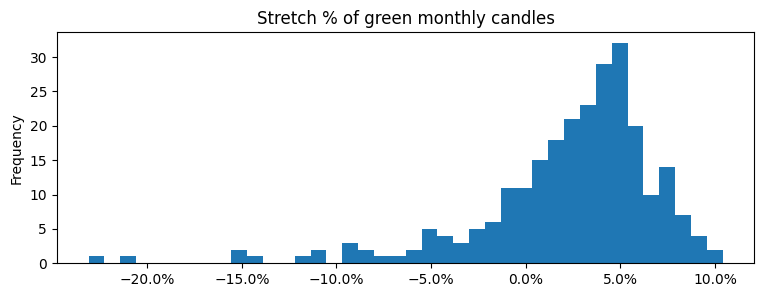

,Open,Close,ema9,stretch,stretch_limit,rsi
Date,,,,,,
1996-03-01,38.270622,38.298374,35.536445,0.076940,0.074206,88.649732
1997-02-01,47.325132,47.588154,43.487063,0.088258,0.074798,84.046961
1997-06-01,51.705075,53.503677,47.580697,0.086682,0.076460,82.929973
1997-07-01,53.617255,57.744572,49.613472,0.080700,0.077011,86.010364
1998-03-01,64.438341,67.308220,59.541188,0.082248,0.077083,83.434044
1998-04-01,67.537816,68.169189,61.266789,0.102356,0.078796,83.972884


In [7]:
# RSI (Wilder's method)
change = df["Close"].diff()
gain = change.clip(lower=0)
loss = -change.clip(upper=0)
avg_gain = gain.ewm(alpha=1 / RSI_PERIOD, adjust=False).mean()
avg_loss = loss.ewm(alpha=1 / RSI_PERIOD, adjust=False).mean()
df["rsi"] = 100 - 100 / (1 + avg_gain / avg_loss)

# Stretch % of green candles: (Open - EMA9) / EMA9
df["green"] = df["Close"] > df["Open"]
df["stretch"] = (df["Open"] - df["ema9"]) / df["ema9"]
green_stretch = df["stretch"].where(df["green"])

# "Far from EMA9" = top 10% of EARLIER green candles (no look-ahead)
df["stretch_limit"] = green_stretch.expanding(min_periods=24).quantile(STRETCH_PCTL).shift(1)

df["overstretched"] = (
    df["green"]
    & (df["stretch"] >= df["stretch_limit"])
    & (df["rsi"] > RSI_LEVEL)
)

# --- the "all %" you asked for
stats = green_stretch.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])
print(f"Green monthly candles: {int(stats['count'])}")
print(stats.drop("count").map("{:.2%}".format).to_string())
print(f"\nGreen candles with RSI > {RSI_LEVEL}: {int((df['green'] & (df['rsi'] > RSI_LEVEL)).sum())}")
print(f"Overstretched (far from EMA9 AND RSI > {RSI_LEVEL}): {int(df['overstretched'].sum())}")

print("\nTop 15 most stretched green candles:")
top = df.loc[df["green"], ["Open", "ema9", "stretch", "rsi"]].nlargest(15, "stretch")
print(top.to_string(formatters={"Open": "{:.2f}".format, "ema9": "{:.2f}".format,
                                "stretch": "{:.2%}".format, "rsi": "{:.1f}".format}))

ax = green_stretch.dropna().plot.hist(bins=40, figsize=(9, 3), title="Stretch % of green monthly candles")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

df.loc[df["overstretched"], ["Open", "Close", "ema9", "stretch", "stretch_limit", "rsi"]]

## Step 8 — Your trading rules

| Rule | Logic |
|---|---|
| **Only in an uptrend** | EMA9 > EMA15 > EMA65 > EMA200 at that month's close. |
| **Buy** | In an uptrend, the month's candle **hits the 15 EMA** (low ≤ EMA15 ≤ high), and we're not already holding. |
| **Sell 1 — overstretched** | A green candle whose stretch % is in the top 10% of earlier green candles **and** RSI > 80. |
| **Sell 2 — broke EMA9** | A monthly **close** below EMA9 (checked from the month after buying). |
| **After selling** | Wait in cash for the next buy signal. |

Every decision is made at the monthly close; the trade itself happens the next month (the shift in Step 9).

**Why a loop?** Each month's action depends on *state* — "am I holding right now?" A loop makes that explicit and easy to explain.

Line notes:
- `buy_signal`: `(df["Low"] <= df["ema15"]) & (df["High"] >= df["ema15"])` = the 15 EMA lies inside the candle's range, i.e. price touched it.
- `position[i] = 1` means "at the close of month *i*, I decided to hold SPY".
- `if in_trade:` runs only in months **after** the buy month, so the buy month can never also be a sell month.
- Sell 1 is checked before Sell 2, so if both happen the reason shown is "overstretched".
- `trades.append({...})` records each buy; at the sale, `trades[-1].update(...)` fills in the sale details. `[-1]` = the last item in a list.
- The trade log at the end lists every trade, why it was sold and its return (before costs). A trade still open at the end is valued at the last close.

In [8]:
df["buy_signal"] = (
    df["uptrend"]
    & (df["Low"] <= df["ema15"])
    & (df["High"] >= df["ema15"])
    & (df.index >= TEST_START)
)

position = np.zeros(len(df))
in_trade = False
trades = []

for i in range(len(df)):
    close = df["Close"].iloc[i]

    if in_trade:
        reason = None
        if df["overstretched"].iloc[i]:
            reason = "overstretched"
        elif close < df["ema9"].iloc[i]:
            reason = "closed below EMA9"
        if reason:
            in_trade = False
            trades[-1].update(sell_month=df.index[i], sell_price=close, reason=reason, sell_i=i)
    elif df["buy_signal"].iloc[i]:
        in_trade = True
        trades.append({"buy_month": df.index[i], "buy_price": close, "buy_i": i})

    position[i] = 1 if in_trade else 0

df["position"] = position

# --- trade log
trade_log = pd.DataFrame(trades, columns=["buy_month", "buy_price", "sell_month",
                                          "sell_price", "reason", "buy_i", "sell_i"])
still_open = trade_log["sell_month"].isna()
trade_log.loc[still_open, "sell_price"] = df["Close"].iloc[-1]
trade_log.loc[still_open, "reason"] = "still open"
trade_log.loc[still_open, "sell_i"] = len(df) - 1
trade_log["months_held"] = (trade_log["sell_i"] - trade_log["buy_i"]).astype(int)
trade_log["return"] = trade_log["sell_price"] / trade_log["buy_price"] - 1
trade_log = trade_log.drop(columns=["buy_i", "sell_i"])

print("Trades:", len(trade_log))
print(trade_log["reason"].value_counts().to_string())
print(f"Win rate (before costs): {(trade_log['return'] > 0).mean():.1%}")
trade_log.style.format({"buy_month": "{:%b %Y}", "sell_month": "{:%b %Y}", "buy_price": "{:.2f}",
                        "sell_price": "{:.2f}", "return": "{:.2%}"}, na_rep="open")

Trades: 14
reason
closed below EMA9    14
Win rate (before costs): 57.1%


,buy_month,buy_price,sell_month,sell_price,reason,months_held,return
0,Aug 2011,93.64,Sep 2011,87.14,closed below EMA9,1,-6.94%
1,Oct 2011,96.65,May 2012,102.33,closed below EMA9,7,5.88%
2,Jun 2012,106.49,Aug 2015,164.40,closed below EMA9,38,54.38%
3,Sep 2015,160.20,Jan 2016,162.91,closed below EMA9,4,1.69%
4,Mar 2016,173.73,Oct 2018,240.10,closed below EMA9,31,38.20%
5,Nov 2018,244.55,Dec 2018,223.02,closed below EMA9,1,-8.80%
6,Jan 2019,240.88,May 2019,246.72,closed below EMA9,4,2.43%
7,Feb 2020,269.38,Mar 2020,235.74,closed below EMA9,1,-12.49%
8,Apr 2020,265.68,Feb 2022,409.82,closed below EMA9,22,54.25%
9,Mar 2022,425.22,Apr 2022,387.90,closed below EMA9,1,-8.78%


## Step 9 — Monthly returns, the one-month shift, and trading costs

| Line | What it does |
|---|---|
| `df["Close"].pct_change()` | Monthly return = Close<sub>this month</sub> ÷ Close<sub>last month</sub> − 1. |
| `held = pd.DataFrame(index=df.index)` | An empty table with the same dates, to hold one column per strategy. |
| `held["Buy & Hold"] = 1.0` | Always 100% invested. |
| `df["position"].shift(1)` | **The key anti-look-ahead line.** A decision made at month *t*'s close can only earn month *t+1*'s return. Without the shift, the backtest would use this month's close to decide whether to own this month's move — information you didn't have yet. |
| `.loc[TEST_START:]` | Keeps only the test period. `.fillna(0)` treats any missing value as "not invested". |
| `turnover = bt_held.diff().abs()` | 1 in any month the position changes (entry or exit), 0 otherwise. |
| `turnover.iloc[0] = bt_held.iloc[0]` | The first month counts as an entry if we start invested (so buy-and-hold pays one cost). |
| `bt_held.mul(bt_ret, axis=0)` | Position × market return, row by row (`axis=0` lines up by date). |
| `- turnover * COST` | Subtracts 0.05% in every month with a trade. |

In [9]:
df["ret"] = df["Close"].pct_change()

held = pd.DataFrame(index=df.index)
held["Buy & Hold"] = 1.0
held["EMA15 Strategy"] = df["position"].shift(1)

bt_held = held.loc[TEST_START:].fillna(0)
bt_ret = df.loc[TEST_START:, "ret"]

turnover = bt_held.diff().abs()
turnover.iloc[0] = bt_held.iloc[0]

strat_ret = bt_held.mul(bt_ret, axis=0) - turnover * COST
strat_ret.head()

,Buy & Hold,EMA15 Strategy
Date,,
2009-09-01,0.034957,0.0
2009-10-01,-0.019225,-0.0
2009-11-01,0.061607,0.0
2009-12-01,0.019101,0.0
2010-01-01,-0.036342,-0.0


## Step 10 — Performance metrics

| Metric | Formula | What it tells you |
|---|---|---|
| **Annual return (CAGR)** | (Final value)<sup>1/years</sup> − 1 | Compound growth rate per year. |
| **Annual volatility** | std(monthly returns) × √12 | How bumpy the ride is. Risk scales with the square root of time. |
| **Sharpe ratio** | mean(monthly) ÷ std(monthly) × √12 | Return per unit of risk. Risk-free rate set to 0 for simplicity (see limitations). |
| **Max drawdown** | min(value ÷ running peak − 1) | Worst peak-to-trough loss. `cummax()` = highest value reached so far. Monthly data hides intra-month lows, so true drawdowns were somewhat deeper. |
| **Win rate (trades)** | % of trades with a positive return after costs | Buy-and-hold is a single trade, so its value is trivial. |
| **Win rate (months)** | % of invested months that were positive | Comparable between the strategy and buy-and-hold. |
| **Time in market** | % of months invested | A strategy in cash half the time *should* have lower volatility. |

Line notes for `trade_returns`:
- `is_in = held_s == 1` → True in invested months.
- `new_trade = is_in & ~is_in.shift(...)` → True in the first month of each trade (`~` means "not").
- `.cumsum()` turns those starting points into trade IDs 1, 2, 3…
- `.groupby(trade_id).prod() - 1` compounds monthly returns within each trade.
- `- 2 * COST` subtracts the buy and sell cost (a close approximation of the exact cost compounding).

In [10]:
def trade_returns(held_s, ret):
    is_in = held_s == 1
    new_trade = is_in & ~is_in.shift(1, fill_value=False)
    trade_id = new_trade.cumsum()
    gross = (1 + ret[is_in]).groupby(trade_id[is_in]).prod() - 1
    return gross - 2 * COST


def performance(r, h):
    equity = (1 + r).cumprod()
    years = len(r) / PERIODS_PER_YEAR
    trades = trade_returns(h, bt_ret)
    in_mkt = h == 1
    return {
        "Annual return (CAGR)": equity.iloc[-1] ** (1 / years) - 1,
        "Total return": equity.iloc[-1] - 1,
        "Annual volatility": r.std() * np.sqrt(PERIODS_PER_YEAR),
        "Sharpe ratio (rf=0)": r.mean() / r.std() * np.sqrt(PERIODS_PER_YEAR),
        "Max drawdown": (equity / equity.cummax() - 1).min(),
        "Win rate (trades)": (trades > 0).mean(),
        "Win rate (months)": (r[in_mkt] > 0).mean(),
        "Number of trades": len(trades),
        "Avg trade return": trades.mean(),
        "Time in market": in_mkt.mean(),
    }


results = pd.DataFrame({name: performance(strat_ret[name], bt_held[name])
                        for name in strat_ret.columns})


def pretty(table):
    out = table.astype(object).copy()
    for row in table.index:
        if row == "Sharpe ratio (rf=0)":
            out.loc[row] = table.loc[row].map("{:.2f}".format)
        elif row == "Number of trades":
            out.loc[row] = table.loc[row].map("{:.0f}".format)
        else:
            out.loc[row] = table.loc[row].map("{:.1%}".format)
    return out


pretty(results)

,Buy & Hold,EMA15 Strategy
Annual return (CAGR),14.5%,7.2%
Total return,909.5%,226.8%
Annual volatility,14.3%,11.1%
Sharpe ratio (rf=0),1.02,0.68
Max drawdown,-23.9%,-30.4%
Win rate (trades),100.0%,57.1%
Win rate (months),68.3%,70.7%
Number of trades,1,14
Avg trade return,909.9%,11.1%
Time in market,100.0%,68.3%


## Step 11 — Plot the growth of $1 and the drawdowns

| Line | What it does |
|---|---|
| `(1 + strat_ret).cumprod()` | Compounds monthly returns into the value of $1 over time. |
| `equity / equity.cummax() - 1` | Drawdown: how far below its previous peak each strategy is in each month. |
| `plt.subplots(2, 1, ..., sharex=True, gridspec_kw=...)` | Two stacked charts sharing the date axis; the top one is 3× taller. |
| `COLORS = {...}` | One fixed color per strategy, used in every chart, so the same strategy always looks the same. Buy & Hold is blue throughout. |
| `equity.plot(ax=ax1, logy=True, color=...)` | One line per strategy. **Log scale**: over many decades a linear chart squashes the early years flat; on a log scale, equal vertical distances mean equal **percentage** changes. |
| `PercentFormatter(1.0)` | Shows −0.25 as "−25%". |
| `FuncFormatter(...)` | Shows the log-scale axis as "$1", "$5" instead of "10⁰". |
| `plt.savefig("equity_curve.png", ...)` | Saves the chart so you can put it in the GitHub README. |

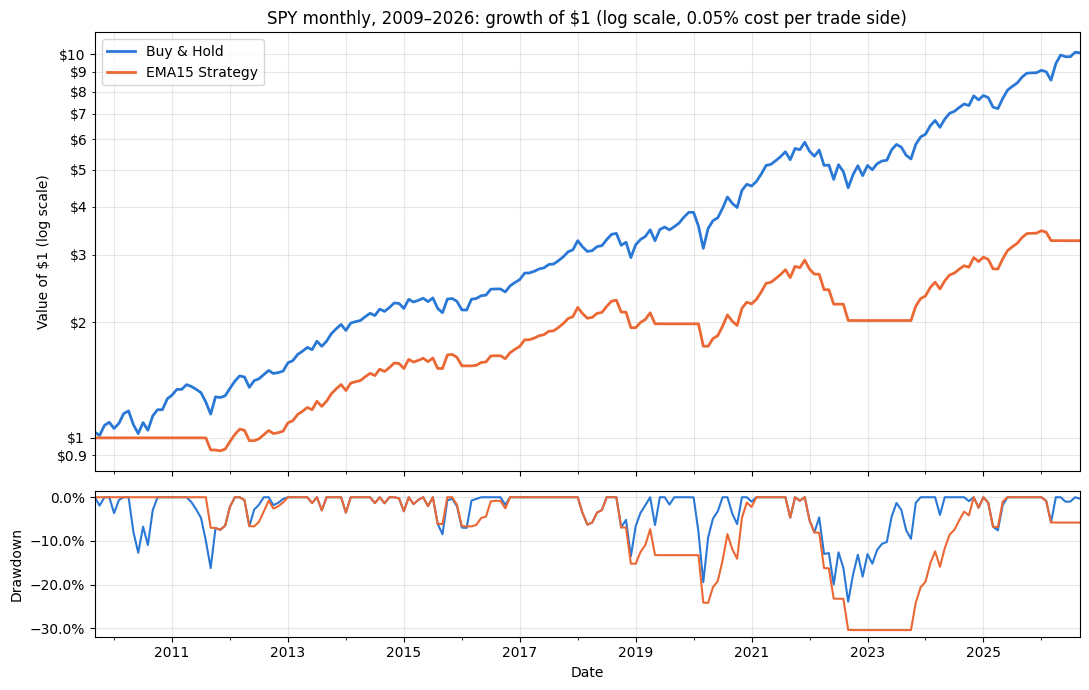

In [11]:
COLORS = {"Buy & Hold": "#2a78d6", "EMA15 Strategy": "#eb6834"}
line_colors = [COLORS[c] for c in strat_ret.columns]

equity = (1 + strat_ret).cumprod()
drawdown = equity / equity.cummax() - 1

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7), sharex=True,
                               gridspec_kw={"height_ratios": [3, 1]})

equity.plot(ax=ax1, logy=True, color=line_colors, linewidth=2)
ax1.set_title(f"{TICKER} monthly, {TEST_START:%Y}–{TEST_END:%Y}: growth of $1 "
              f"(log scale, {COST:.2%} cost per trade side)")
ax1.set_ylabel("Value of $1 (log scale)")
ax1.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"${v:,.2g}"))
ax1.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"${v:,.2g}"))
ax1.grid(alpha=0.3, which="both")

drawdown.plot(ax=ax2, legend=False, color=line_colors, linewidth=1.5)
ax2.set_ylabel("Drawdown")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("equity_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 11b — Compare your strategy with buy-and-hold

Six bar charts, one per metric, so your strategy can be compared with **Buy & Hold** at a glance. The value is printed on every bar.

How to read it: higher is better for return and Sharpe; for volatility and drawdown, **closer to zero** is better (less risk). Time in market shows how much of the period your strategy was actually invested.

Line notes:
- `plt.subplots(2, 3, ...)` → a grid of 2 rows × 3 charts; `axes.flat` lets us loop over them one by one.
- `results.loc[metric]` → one row of the results table (that metric for every strategy).
- `ax.bar(...)` draws the bars in each strategy's fixed color.
- `ax.bar_label(...)` writes the value on each bar.
- `ax.axhline(0, ...)` draws the zero line so negatives (drawdowns) read clearly.

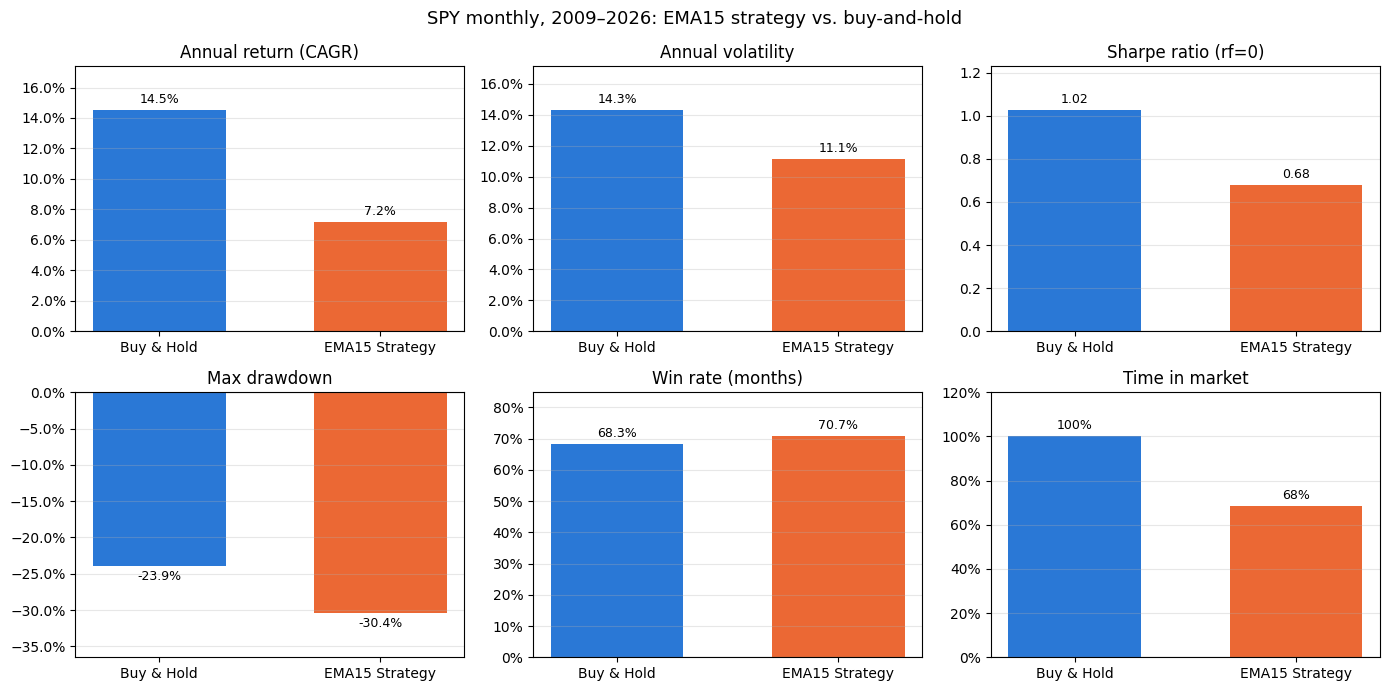

In [12]:
metrics_to_plot = [
    ("Annual return (CAGR)", "{:.1%}"),
    ("Annual volatility", "{:.1%}"),
    ("Sharpe ratio (rf=0)", "{:.2f}"),
    ("Max drawdown", "{:.1%}"),
    ("Win rate (months)", "{:.1%}"),
    ("Time in market", "{:.0%}"),
]
names = list(results.columns)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (metric, fmt) in zip(axes.flat, metrics_to_plot):
    values = results.loc[metric].astype(float)
    bars = ax.bar(names, values, color=[COLORS[n] for n in names], width=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], padding=3, fontsize=9)
    ax.axhline(0, color="#888888", linewidth=0.8)
    ax.set_title(metric)
    ax.tick_params(axis="x", labelsize=10)
    ax.margins(y=0.2)
    if fmt.endswith("%}"):
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(axis="y", alpha=0.3)

fig.suptitle(f"{TICKER} monthly, {TEST_START:%Y}–{TEST_END:%Y}: EMA15 strategy vs. buy-and-hold", fontsize=13)
plt.tight_layout()
plt.savefig("metrics_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 11c — See your trades on the monthly chart

SPY's monthly close with the four EMAs, plus every trade of your EMA15 strategy:
- **▲ green** = buy (candle touched EMA15 in an uptrend)
- **▼ red** = sell because the month closed below EMA9
- **★ red** = sell because the candle was overstretched with RSI > 80
- **Gray shading** = months you were holding SPY

This is the best chart for checking that the code does what you intended — look at a few trades and confirm each one by eye against your own chart.

Line notes:
- `plot_df = df.loc[TEST_START:]` → only the test period.
- `ax.plot(...)` draws the close and the EMAs. The EMA names are written at the right end of each line; `max(y, label_y * 1.05)` pushes a label up if it would sit on top of the one below it.
- `FuncFormatter(lambda v, _: f"{v:,.0f}")` shows the log-scale price axis as plain numbers.
- `ax.axvspan(start, end, ...)` shades the holding period of each trade.
- `ax.scatter(...)` draws the buy/sell markers; `zorder=5` puts them on top of the lines.
- `trade_log["reason"] == "overstretched"` picks out the sells caused by Sell 1.

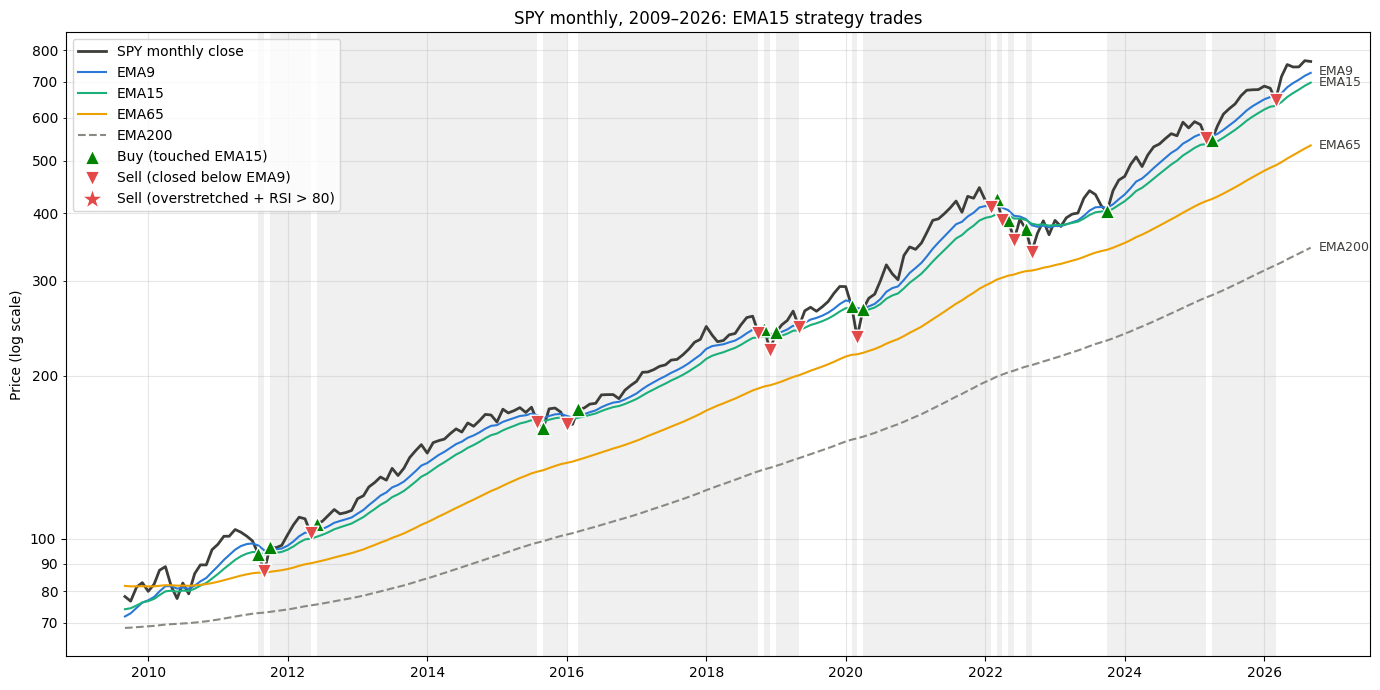

In [13]:
plot_df = df.loc[TEST_START:]
ema_colors = {"ema9": "#2a78d6", "ema15": "#1baf7a", "ema65": "#eda100", "ema200": "#8a8a85"}

fig, ax = plt.subplots(figsize=(14, 7))
ax.plot(plot_df.index, plot_df["Close"], color="#3d3d3a", linewidth=2, label=f"{TICKER} monthly close")
for col, color in ema_colors.items():
    ax.plot(plot_df.index, plot_df[col], color=color, linewidth=1.5,
            linestyle="--" if col == "ema200" else "-", label=col.upper())

# label each EMA at the right end, nudged apart so labels don't overlap
label_y = None
for col in sorted(ema_colors, key=lambda c: plot_df[c].iloc[-1]):
    y = plot_df[col].iloc[-1]
    label_y = y if label_y is None else max(y, label_y * 1.05)
    ax.annotate(col.upper(), xy=(plot_df.index[-1], label_y), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#3d3d3a")

for _, t in trade_log.iterrows():
    end = t["sell_month"] if pd.notna(t["sell_month"]) else plot_df.index[-1]
    ax.axvspan(t["buy_month"], end, color="#888888", alpha=0.12, linewidth=0)

ax.scatter(trade_log["buy_month"], trade_log["buy_price"], marker="^", s=110, color="#008300",
           edgecolor="white", linewidth=1, zorder=5, label="Buy (touched EMA15)")
sold = trade_log[trade_log["sell_month"].notna()]
ema9_sells = sold[sold["reason"] == "closed below EMA9"]
stretch_sells = sold[sold["reason"] == "overstretched"]
ax.scatter(ema9_sells["sell_month"], ema9_sells["sell_price"], marker="v", s=110, color="#e34948",
           edgecolor="white", linewidth=1, zorder=5, label="Sell (closed below EMA9)")
ax.scatter(stretch_sells["sell_month"], stretch_sells["sell_price"], marker="*", s=260, color="#e34948",
           edgecolor="white", linewidth=1, zorder=5, label="Sell (overstretched + RSI > 80)")

ax.set_yscale("log")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title(f"{TICKER} monthly, {TEST_START:%Y}–{TEST_END:%Y}: EMA15 strategy trades")
ax.set_ylabel("Price (log scale)")
ax.grid(alpha=0.3, which="both")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig("trades_chart.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 12 — Sanity check: what if we forgot the one-month shift?

This re-runs your EMA15 strategy **without** `.shift(1)` — i.e., cheating by using this month's close to own this month's move. The gap between the two numbers is how much look-ahead bias would have distorted the result. This is a strong interview talking point: it shows you know *why* the shift is there, not just that it is.

In [14]:
cheat_ret = df.loc[TEST_START:, "position"] * bt_ret          # no shift = look-ahead
cheat_cagr = (1 + cheat_ret).prod() ** (PERIODS_PER_YEAR / len(cheat_ret)) - 1
honest_cagr = results.loc["Annual return (CAGR)", "EMA15 Strategy"]

print(f"EMA15 Strategy CAGR, honest (shifted):               {honest_cagr:.2%}")
print(f"EMA15 Strategy CAGR, look-ahead (no shift, no costs): {cheat_cagr:.2%}")

EMA15 Strategy CAGR, honest (shifted):               7.18%
EMA15 Strategy CAGR, look-ahead (no shift, no costs): 15.40%


## Step 13 — Export results for the README

- The three charts were saved as `equity_curve.png`, `metrics_comparison.png` and `trades_chart.png` — download them for the README.
- `.to_csv(...)` saves the tables as files (find them in Colab's 📁 Files panel on the left; right-click → Download).
- `.to_markdown()` prints a table in Markdown format — copy the printed output straight into `README.md`.

In [15]:
results.to_csv("results.csv")
event_summary.to_csv("event_study.csv")
events.to_csv("pullback_events.csv", index=False)
trade_log.to_csv("trade_log.csv", index=False)

print(f"### Strategy performance ({TICKER}, monthly, {TEST_START:%b %Y} – {TEST_END:%b %Y})\n")
print(pretty(results).to_markdown())

event_pretty = event_summary.copy().astype(object)
for col in event_summary.columns:
    fmt = "{:.0f}" if col == "events" else "{:.1f}" if col == "avg_months" else "{:.1%}"
    event_pretty[col] = event_summary[col].map(lambda x: fmt.format(x) if pd.notna(x) else "–")
print("\n### Pullback event study\n")
print(event_pretty.to_markdown())

### Strategy performance (SPY, monthly, Sep 2009 – Sep 2026)

|                      | Buy & Hold   | EMA15 Strategy   |
|:---------------------|:-------------|:-----------------|
| Annual return (CAGR) | 14.5%        | 7.2%             |
| Total return         | 909.5%       | 226.8%           |
| Annual volatility    | 14.3%        | 11.1%            |
| Sharpe ratio (rf=0)  | 1.02         | 0.68             |
| Max drawdown         | -23.9%       | -30.4%           |
| Win rate (trades)    | 100.0%       | 57.1%            |
| Win rate (months)    | 68.3%        | 70.7%            |
| Number of trades     | 1            | 14               |
| Avg trade return     | 909.9%       | 11.1%            |
| Time in market       | 100.0%       | 68.3%            |

### Pullback event study

|       |   events | bounce_rate   | fail_rate   | timeout_rate   | avg_return   | avg_return_bounce   | avg_return_fail   |   avg_months |
|:------|---------:|:--------------|:------------|:------------

## Ideas to extend (and to discuss in an interview)

- **Longer history:** set `TICKER = "^GSPC"` (the S&P 500 index, back to the late 1920s) for many more signals. Trade-off: the index excludes dividends and can't be bought directly.
- **Different thresholds:** try `STRETCH_PCTL` = 0.80 / 0.95 and `RSI_LEVEL` = 70 / 75 and see whether conclusions hold.
- **Out-of-sample test:** run the exact same rules, unchanged, on other markets (e.g. `^IXIC` Nasdaq, `^N225` Nikkei, `^FTSE`). If it only works on SPY, that's a warning sign.
- **Sub-periods:** split the test into halves (e.g. before/after 1990) and check the conclusion holds in both.
- **Sensitivity:** vary `SWING_LOOKBACK` (6/12/24) and `COST` and see whether conclusions hold.
- **Cash earns T-bill yield** and Sharpe uses a real risk-free rate.